# Analyse et Traitement de Données Hospitalières
**Auteur :** Vincent DA SILVA

**Objectif du notebook :**
Ce document présente le traitement d'un export brut de Dossier Patient Informatisé (DPI). Il contient les étapes de fiabilisation d'un jeu de données synthétique (séjours hospitaliers) et la préparation des données en vue d'en extraire des indicateurs de pilotage.

## Partie 1 — Data : séjours hospitaliers

### 1.1 — Audit qualité
Exploration du fichier `sejours.csv` pour lister et justifier les anomalies détectées, puis génération du fichier fiabilisé `sejours_clean.csv`.

### 1.1 — Audit qualité des données

En explorant le dataset, j'ai identifié pas mal de problèmes de qualité, assez typiques d'un export brut. Voici ce que j'ai repéré avant de passer au nettoyage :

* **Doublons sur la clé primaire :** Sur les 1 230 observations, je ne compte que 1 220 id_sejour uniques. J'ai repéré 9 doublons (des lignes parfaitement identiques) et un autre doublon où seul le format de date change. L'id_sejour devant être unique, il faut absolument drop ces duplicatas pour ne pas fausser les futurs KPIs.
* **Outliers (Valeurs aberrantes) sur les âges :** J'ai isolé 6 patients avec des âges physiquement impossibles (-3, 142, 250, 999). Le 999 est probablement utilisé par le système pour combler une valeur manquante, tandis que les autres ressemblent fort à des erreurs de saisie.
* **Incohérences logiques sur les dates :** J'ai 8 séjours où la date_sortie est enregistrée avant la date_entree. C'est logiquement impossible, probablement dû à des inversions jour/mois lors de la saisie manuelle.
* **Formats de dates hétérogènes (Parsing) :** La majorité des dates est au standard ISO (YYYY-MM-DD), mais j'ai trouvé 25 dates d'entrée au format français (DD/MM/YYYY). Par ailleurs, on a 15 date_sortie manquantes (NaN) : c'est des patients toujours en cours d'hospitalisation.
* **Problèmes de typographie et casse :**
  * **Service :** On se retrouve avec 22 valeurs uniques simplement à cause d'espaces superflus ou de casses différentes (`URG`, `urg`, ` URG`, `URG `). En uniformisant, on retombe bien sur 7 services uniques.
  * **Mode de sortie :** Même constat, le vocabulaire et la casse ne sont pas standardisés (`Domicile` vs `domicile`, ou `DCD` au lieu de `deces`). Je note aussi 6 valeurs nulles sur cette colonne.

In [65]:
import pandas as pd
import numpy as np

df = pd.read_csv('sejours.csv')

df['date_entree'] = pd.to_datetime(df['date_entree'], format='mixed', dayfirst=True)
df['date_sortie'] = pd.to_datetime(df['date_sortie'], format='mixed', dayfirst=True)

df['service'] = df['service'].str.strip().str.upper()
df['mode_sortie'] = df['mode_sortie'].replace({'Domicile': 'domicile', 'DCD': 'deces'})

df = df.drop_duplicates(subset=['id_sejour'], keep='first')

invalid_age_mask = (df['age'] < 0) | (df['age'] > 120)
df.loc[invalid_age_mask, 'age'] = np.nan

inverted_dates_mask = df['date_sortie'] < df['date_entree']
df.loc[inverted_dates_mask, 'date_sortie'] = pd.NaT

df.to_csv('sejours_clean.csv', index=False)

## Partie 1.2 — Calcul des Indicateurs

In [66]:
# 1.2.1 DMS par service (séjours terminés)
df_term = df.dropna(subset=['date_sortie']).copy()
df_term['DMS'] = (df_term['date_sortie'] - df_term['date_entree']) / pd.Timedelta(days=1)
print("--- 1. DMS par Service (en jours) ---")
display(df_term.groupby('service')['DMS'].agg(['mean', 'median']).round(1))

# 1.2.2 Taux de réhospitalisation à 30 jours
df_tri = df.sort_values(['id_patient', 'date_entree'])
delai = (df_tri['date_entree'] - df_tri.groupby('id_patient')['date_sortie'].shift()).dt.days
taux = (delai.between(0, 30).sum() / len(df_term)) * 100
print(f"\n--- 2. Taux de réhospitalisation à 30 jours ---")
print(f"Taux de réhospitalisation : {taux:.2f} %")

# 1.2.3 Nombre d'entrées par mois et par service
print("\n--- 3. Flux d'entrées mensuel par service ---")
flux_mensuel = pd.crosstab(df['date_entree'].dt.to_period('M'), df['service'])
display(flux_mensuel)

--- 1. DMS par Service (en jours) ---


,mean,median
service,,
CHIR,5.9,4.1
MAT,3.9,2.8
MED,4.9,3.2
PED,4.0,2.7
REA,6.9,5.0
SSR,17.1,12.4
URG,3.2,2.2



--- 2. Taux de réhospitalisation à 30 jours ---
Taux de réhospitalisation : 5.26 %

--- 3. Flux d'entrées mensuel par service ---


service,CHIR,MAT,MED,PED,REA,SSR,URG
date_entree,,,,,,,
2025-01,18,12,18,5,6,9,29
2025-02,11,14,14,10,7,12,17
2025-03,17,9,21,14,10,10,36
2025-04,21,11,29,8,4,10,24
2025-05,14,10,27,10,8,8,24
2025-06,14,12,22,8,7,12,18
2025-07,23,7,22,7,12,6,25
2025-08,14,7,20,13,7,6,25
2025-09,15,13,17,9,9,7,23


### 1.3 — Visualisation des données

Pour proposer une lecture simplifiée à un directeur d'hôpital, voici deux graphiques clés :
1. **Un Boxplot de la DMS par service** : Idéal pour repérer non seulement la médiane (plus robuste que la moyenne face aux longs séjours), mais aussi la dispersion et les patients avec des valeurs aberrantes.
2. **Une courbe d'évolution des entrées mensuelles** : Permet de repérer facilement la saisonnalité (ex: pic aux urgences en hiver).

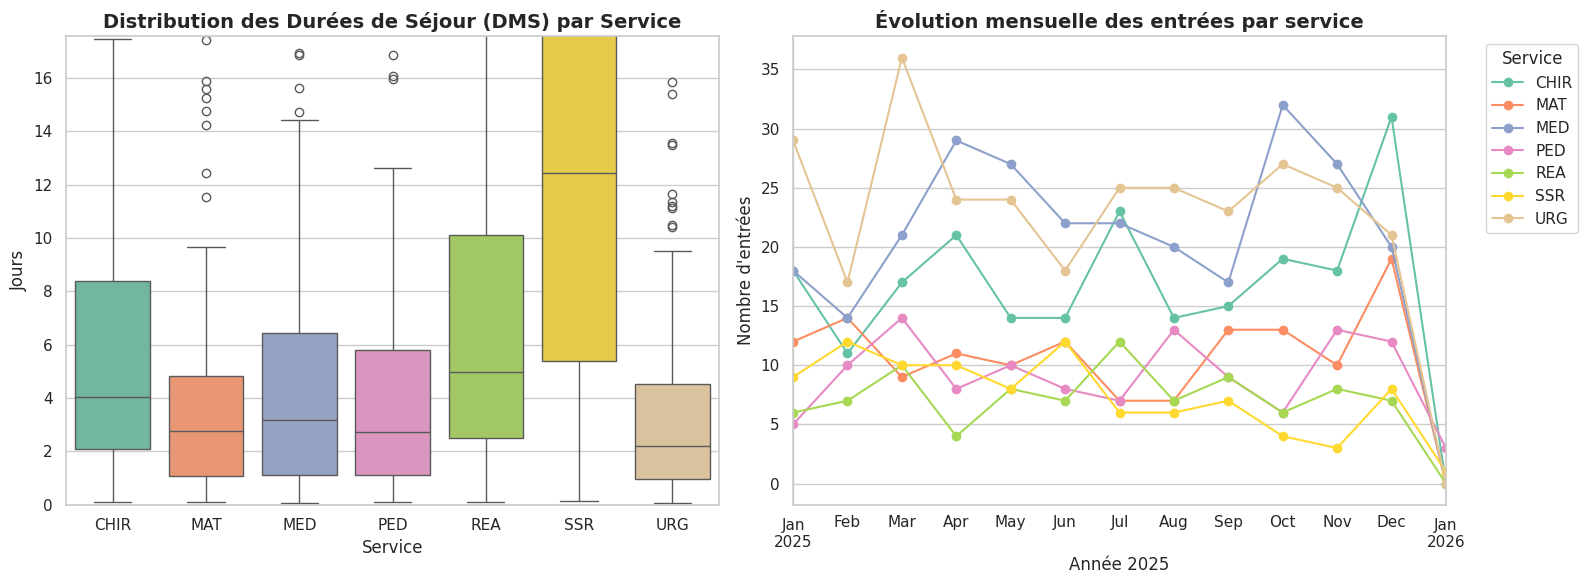

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
services_tries = sorted(df_term['service'].dropna().unique())
mes_couleurs = sns.color_palette("Set2", n_colors=len(services_tries))

# Graphique 1 : Boxplot de la DMS par service
sns.boxplot(
    data=df_term, x='service', y='DMS', ax=axes[0],
    hue='service', legend=False,
    order=services_tries,
    hue_order=services_tries,
    palette=mes_couleurs
)
axes[0].set_title('Distribution des Durées de Séjour (DMS) par Service', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Jours')
axes[0].set_xlabel('Service')
# Optionnel : limiter l'axe Y pour masquer les valeurs extrêmes et mieux voir les boîtes
axes[0].set_ylim(0, df_term['DMS'].quantile(0.95))

# Graphique 2 : Évolution des entrées
flux_mensuel.plot(kind='line', marker='o', ax=axes[1], color=mes_couleurs)
axes[1].set_title('Évolution mensuelle des entrées par service', fontsize=14, fontweight='bold')
axes[1].set_ylabel("Nombre d'entrées")
axes[1].set_xlabel('Année 2025')
axes[1].legend(title='Service', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

### Question Bonus : Le taux de réhospitalisation est-il un bon indicateur de qualité ?

Oui, c'est un bon indicateur de base. Si beaucoup de patients reviennent très vite à l'hôpital, ça veut souvent dire qu'ils sont sortis trop tôt ou qu'il y a eu des complications à la maison.

Mais ce calcul brut a deux gros défauts :

1. Il mélange les retours prévus et les urgences : Si un patient revient 15 jours après pour une chimio prévue ou pour enlever des points de suture, le calcul compte ça comme une anomalie, alors que c'est tout à fait normal.

2. Il ignore l'état de santé des patients : Un hôpital qui soigne des personnes très âgées et fragiles aura forcément plus de retours qu'une clinique qui fait de petites opérations faciles. Ça ne veut pas dire que l'hôpital travaille mal, c'est juste que ses patients sont plus vulnérables au départ.